In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

path = "data/train.csv"
data = pd.read_csv(path)
data

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41996,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41997,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41998,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [2]:
data.columns

Index(['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5',
       'pixel6', 'pixel7', 'pixel8',
       ...
       'pixel774', 'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779',
       'pixel780', 'pixel781', 'pixel782', 'pixel783'],
      dtype='object', length=785)

In [3]:
data = np.array(data)

In [4]:
data

array([[1, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       ...,
       [7, 0, 0, ..., 0, 0, 0],
       [6, 0, 0, ..., 0, 0, 0],
       [9, 0, 0, ..., 0, 0, 0]], dtype=int64)

In [5]:
m,n = data.shape
m,n

(42000, 785)

In [6]:
data = np.array(data)
m, n = data.shape
np.random.shuffle(data) 

data_dev = data[0:1000].T
Y_dev = data_dev[0]
X_dev = data_dfev[1:n]
X_dev = X_dev / 255.

data_train = data[1000:m].T
Y_train = data_train[0]
X_train = data_train[1:n]
X_train = X_train / 255.
_,m_train = X_train.shape

In [21]:
print('data shape: {}'.format(data.shape))
print('data_dev shape: {}'.format(data_dev.shape))
print('\n')
print('Y_dev shape: {}'.format(Y_dev.shape))
print('X_dev shape: {}'.format(X_dev.shape))
print('\n')
print('data_train shape: {}'.format(data_train.shape))
print('\n')
print('Y_train shape: {}'.format(Y_train.shape))
print('X_train shape: {}'.format(X_train.shape))

data shape: (42000, 785)
data_dev shape: (785, 1000)


Y_dev shape: (1000,)
X_dev shape: (784, 1000)


data_train shape: (785, 41000)


Y_train shape: (41000,)
X_train shape: (784, 41000)


In [27]:
def init_params():
    W1 = np.random.rand(10, 784) - 0.5
    b1 = np.random.rand(10, 1) - 0.5
    W2 = np.random.rand(10, 10) - 0.5
    b2 = np.random.rand(10, 1) - 0.5
    return W1, b1, W2, b2

def ReLU(Z):
    return np.maximum(Z, 0)

def softmax(Z):
    A = np.exp(Z) / sum(np.exp(Z))
    return A
def forward_prop(W1, b1, W2, b2, X):
    Z1 = W1.dot(X) + b1
    A1 = ReLU(Z1)
    Z2 = W2.dot(A1) + b2
    A2 = softmax(Z2)
    return Z1, A1, Z2, A2

def ReLU_deriv(Z):
    return Z > 0

def one_hot(Y):
    one_hot_Y = np.zeros((Y.size, Y.max() + 1))
    one_hot_Y[np.arange(Y.size), Y] = 1
    one_hot_Y = one_hot_Y.T
    return one_hot_Y
def backward_prop(Z1, A1, Z2, A2, W1, W2, X, Y):
    one_hot_Y = one_hot(Y)
    dZ2 = A2 - one_hot_Y
    dW2 = 1 / m * dZ2.dot(A1.T)
    db2 = 1 / m * np.sum(dZ2)
    dZ1 = W2.T.dot(dZ2) * ReLU_deriv(Z1)
    dW1 = 1 / m * dZ1.dot(X.T)
    db1 = 1 / m * np.sum(dZ1)
    return dW1, db1, dW2, db2

def update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha):
    W1 = W1 - alpha * dW1
    b1 = b1 - alpha * db1    
    W2 = W2 - alpha * dW2  
    b2 = b2 - alpha * db2    
    return W1, b1, W2, b2

In [28]:
def get_predictions(A2):
    return np.argmax(A2, 0)

def get_accuracy(predictions, Y):
    print(predictions, Y)
    return np.sum(predictions == Y) / Y.size

def gradient_descent(X, Y, alpha, iterations):
    W1, b1, W2, b2 = init_params()
    for i in range(iterations):
        Z1, A1, Z2, A2 = forward_prop(W1, b1, W2, b2, X)
        dW1, db1, dW2, db2 = backward_prop(Z1, A1, Z2, A2, W1, W2, X, Y)
        W1, b1, W2, b2 = update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha)
        if i % 10 == 0:
            print("Iteration: ", i)
            predictions = get_predictions(A2)
            print(get_accuracy(predictions, Y))
    return W1, b1, W2, b2

In [29]:
W1, b1, W2, b2 = gradient_descent(X_train, Y_train, 0.10, 500)

Iteration:  0
[6 1 1 ... 5 2 2] [4 1 0 ... 2 4 1]
0.07675609756097561
Iteration:  10
[4 1 0 ... 5 6 2] [4 1 0 ... 2 4 1]
0.1808780487804878
Iteration:  20
[4 1 0 ... 5 7 1] [4 1 0 ... 2 4 1]
0.2691707317073171
Iteration:  30
[4 1 0 ... 5 9 1] [4 1 0 ... 2 4 1]
0.34397560975609753
Iteration:  40
[4 1 0 ... 5 9 1] [4 1 0 ... 2 4 1]
0.4055365853658537
Iteration:  50
[4 1 0 ... 5 9 1] [4 1 0 ... 2 4 1]
0.45507317073170733
Iteration:  60
[4 1 0 ... 2 4 1] [4 1 0 ... 2 4 1]
0.4974390243902439
Iteration:  70
[4 1 0 ... 2 4 1] [4 1 0 ... 2 4 1]
0.5350243902439025
Iteration:  80
[4 1 0 ... 2 4 1] [4 1 0 ... 2 4 1]
0.5664390243902439
Iteration:  90
[4 1 0 ... 2 4 1] [4 1 0 ... 2 4 1]
0.593609756097561
Iteration:  100
[4 1 0 ... 2 4 1] [4 1 0 ... 2 4 1]
0.6179756097560976
Iteration:  110
[4 1 0 ... 2 4 1] [4 1 0 ... 2 4 1]
0.6382682926829268
Iteration:  120
[4 1 0 ... 2 4 1] [4 1 0 ... 2 4 1]
0.6551463414634147
Iteration:  130
[4 1 0 ... 2 4 1] [4 1 0 ... 2 4 1]
0.6711463414634147
Iteration:  140

In [30]:
def make_predictions(X, W1, b1, W2, b2):
    _, _, _, A2 = forward_prop(W1, b1, W2, b2, X)
    predictions = get_predictions(A2)
    return predictions

def test_prediction(index, W1, b1, W2, b2):
    current_image = X_train[:, index, None]
    prediction = make_predictions(X_train[:, index, None], W1, b1, W2, b2)
    label = Y_train[index]
    print("Prediction: ", prediction)
    print("Label: ", label)

    current_image = current_image.reshape((28, 28)) * 255
    plt.gray()
    plt.imshow(current_image, interpolation='nearest')
    plt.show()

Prediction:  [4]
Label:  4


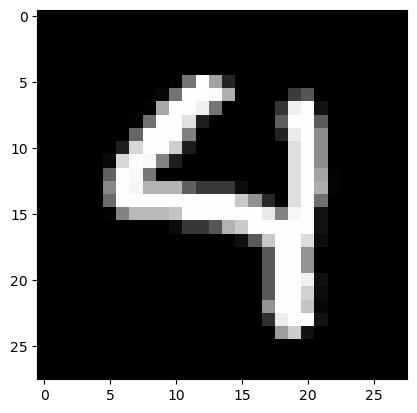

Prediction:  [1]
Label:  1


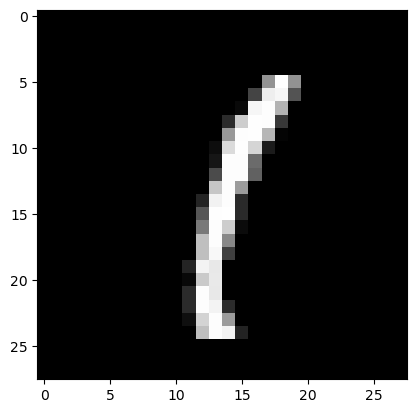

Prediction:  [0]
Label:  0


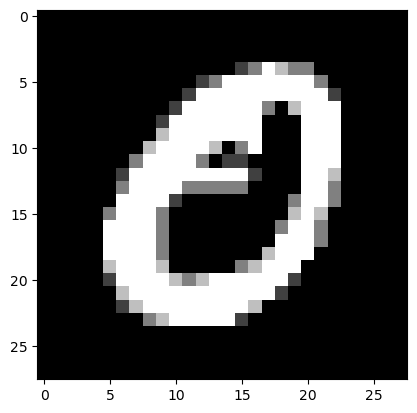

Prediction:  [8]
Label:  8


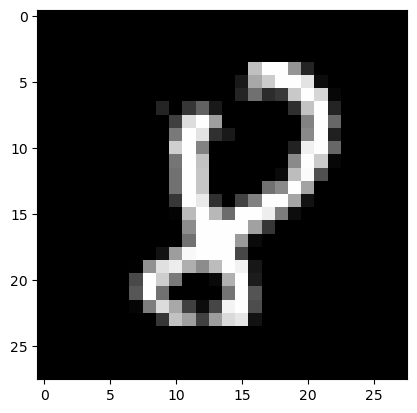

In [31]:
test_prediction(0, W1, b1, W2, b2)
test_prediction(1, W1, b1, W2, b2)
test_prediction(2, W1, b1, W2, b2)
test_prediction(3, W1, b1, W2, b2)

In [32]:
dev_predictions = make_predictions(X_dev, W1, b1, W2, b2)
get_accuracy(dev_predictions, Y_dev)

[0 5 8 2 6 1 3 0 5 6 3 8 8 0 8 5 7 2 0 1 7 6 2 6 0 4 4 7 0 3 9 8 5 8 8 5 9
 1 9 5 1 8 7 0 9 7 7 0 4 7 7 2 0 0 8 7 4 6 0 8 6 7 6 7 9 8 2 0 2 3 5 9 2 2
 5 6 3 0 0 3 7 2 4 7 2 7 3 2 6 3 6 4 2 9 0 4 2 1 1 0 6 1 6 1 0 3 3 7 9 5 2
 7 8 7 8 4 1 1 7 4 1 4 7 6 4 8 0 9 1 7 3 0 5 7 4 4 4 1 6 0 7 8 1 0 9 6 2 9
 2 3 7 6 5 1 6 1 4 6 3 4 7 8 8 6 6 5 3 1 0 4 8 2 9 0 9 9 7 4 8 0 9 3 2 5 3
 3 7 7 0 8 6 1 7 1 5 4 3 9 0 5 7 8 9 6 0 6 2 0 3 8 7 0 6 0 1 9 7 9 8 6 8 3
 0 0 0 6 6 1 1 3 6 0 7 9 5 6 5 8 1 4 1 0 3 6 6 0 3 0 3 0 9 0 9 6 6 1 6 4 8
 7 7 3 9 2 1 8 9 2 3 3 2 8 7 2 8 5 8 6 9 7 8 8 0 0 7 6 1 4 6 8 0 8 7 5 3 9
 5 7 6 7 4 6 0 4 0 3 2 4 4 8 7 2 8 7 2 8 7 4 3 2 4 3 0 5 1 7 1 9 8 0 0 4 5
 6 7 6 2 9 9 3 1 6 3 7 9 9 4 6 3 8 8 2 9 3 8 4 5 4 3 0 7 0 8 6 5 6 9 4 8 2
 7 3 7 9 4 4 4 1 5 7 9 1 4 5 9 2 0 8 3 3 8 5 0 7 7 3 3 9 6 1 0 8 3 0 1 9 5
 9 2 8 2 8 0 7 2 6 2 7 9 5 6 2 1 5 1 8 8 2 7 0 5 1 7 7 7 3 7 0 1 7 4 3 4 0
 4 2 1 4 3 6 5 8 9 2 2 3 4 3 5 6 4 6 4 0 9 8 0 5 1 2 4 7 3 7 4 9 9 9 5 4 1
 6 0 4 1 1 8 3 3 2 7 1 5 

0.841